# Stage 1: RUHSOLD Baselines (Roman Urdu Hate-Speech Detection)
CS-245 Machine Learning term project. This notebook covers **Stage 1** of the plan: train and evaluate classifiers on RUHSOLD only.

**Contents**
1. Load data and check it
2. Exploratory analysis (class balance, lengths, duplicates and leakage)
3. Cleaning pipeline
4. Baselines: word vs character features, LR vs SVM, tuned with 5-fold CV
5. Imbalance check (class weights on/off)
6. Final test evaluation (run once)
7. Calibration (needed for Stage 2)
8. Error analysis, top features, learning curve
9. Save results and model

**Label convention used below:** `y = 1` means **Hate/Offensive** (the positive class), `y = 0` means **Normal**. In the raw files the coding is reversed (0 = Abusive/Offensive, 1 = Normal), so it is flipped once, on load.

In [1]:
import re, csv, os, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, learning_curve
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.calibration import calibration_curve

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)

## 1. Load the data
The official RUHSOLD files (coarse-grained task) are read straight from the authors' GitHub repository. This avoids the Hugging Face loading script, which hides the test labels.

Note: the TSV files have no header row, and tweets contain quote characters, so quoting is switched off when parsing.

In [2]:
BASE = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/"

def load_split(name):
    df = pd.read_csv(BASE + f"task_1_{name}.tsv", sep="\t", header=None,
                     names=["tweet", "raw_label"], quoting=csv.QUOTE_NONE,
                     encoding="utf-8", dtype=str, keep_default_na=False)
    df["raw_label"] = df["raw_label"].str.strip().astype(int)
    df["y"] = (df["raw_label"] == 0).astype(int)   # 1 = Hate/Offensive, 0 = Normal
    df["tweet"] = df["tweet"].str.strip()
    return df

train, val, test = load_split("train"), load_split("validation"), load_split("test")
print({"train": len(train), "val": len(val), "test": len(test)})
train.head()

{'train': 7209, 'val': 801, 'test': 2003}


,tweet,raw_label,y
0,pichwara se akhrot kahe fod rahe ho chicha,1,0
1,bhaunk bhaunk ke pagal ho jaata ab tak....,0,1
2,shivsaina nam mulla saina rakh hijra uddh...,0,1
3,there are some yahodi daboo like imran chore z...,0,1
4,"chutiye ye hunduism ni he islam he , isme koi ...",0,1


## 2. Exploratory analysis
**Check the synopsis assumptions:** the synopsis assumed Normal far outnumbers Hate/Offensive. Verify it below.

y,Normal,Hate/Offensive,% Hate/Offensive
train,3851,3358,46.6
val,428,373,46.6
test,1070,933,46.6


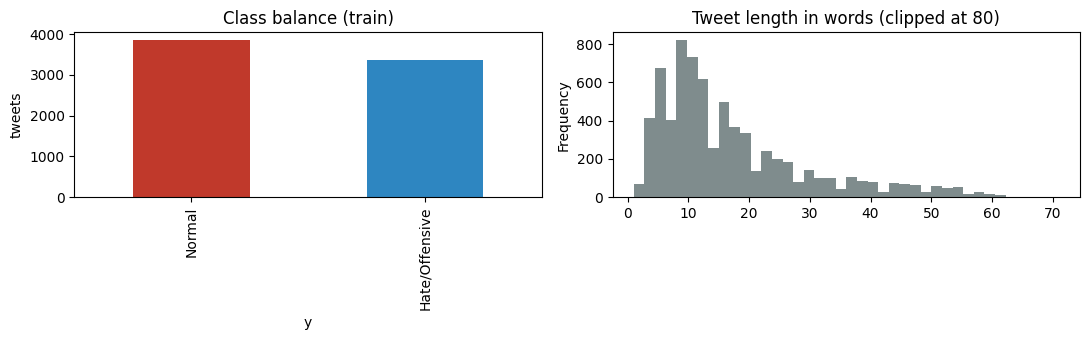

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
Normal,3851.0,16.177616,12.179806,1.0,8.0,12.0,20.0,71.0
Hate/Offensive,3358.0,18.125670,13.022345,1.0,8.0,14.0,24.0,65.0


In [3]:
summary = pd.DataFrame({
    s: d["y"].value_counts().rename({1: "Hate/Offensive", 0: "Normal"})
    for s, d in [("train", train), ("val", val), ("test", test)]
}).T
summary["% Hate/Offensive"] = (100 * summary["Hate/Offensive"] / summary.sum(axis=1)).round(1)
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train["y"].map({1: "Hate/Offensive", 0: "Normal"}).value_counts().plot.bar(ax=ax[0], color=["#c0392b", "#2e86c1"])
ax[0].set_title("Class balance (train)"); ax[0].set_ylabel("tweets")
train["tweet"].str.split().str.len().clip(upper=80).plot.hist(bins=40, ax=ax[1], color="#7f8c8d")
ax[1].set_title("Tweet length in words (clipped at 80)")
plt.tight_layout(); plt.savefig("figures/eda_balance_length.png", dpi=150); plt.show()

train["n_words"] = train["tweet"].str.split().str.len()
display(train.groupby("y")["n_words"].describe().rename(index={1: "Hate/Offensive", 0: "Normal"}))

In [4]:
# Read real examples from each class (use these as quoted examples in the report)
pd.set_option("display.max_colwidth", 140)
print("--- Hate/Offensive ---")
display(train[train.y == 1].sample(15, random_state=SEED)[["tweet"]])
print("--- Normal ---")
display(train[train.y == 0].sample(15, random_state=SEED)[["tweet"]])

--- Hate/Offensive ---


,tweet
2493,ye bat bharwe nawaz ki batata na tu gandooo
3601,hmm tera baap tha na woh.
2956,tumhari maa ke liye nahi bola naa baap ke liye bola sid ne tum dono bhai gire hue kism ke insaan ho poore show mein sid ki ek bhi famil...
3705,charsi gaffora fir aa gaya yahan muh se tatti karne 🤣🤣🤣
403,kia akhrot qaum hai.
5078,ajeeb randi rona hai tmhara khtm h nhi hta
4161,"woh toh hum logon ne parliament me dekh hi lia tha. jab amit shah said, owaisi tereko sun na padega during 370 discussion. waise owaisi..."
2539,begherat orat ... apne alfaz dekh tere ko to khinzeer ki olad b kehna ghalt hoga tu usse b gai guzri hai
2496,randi of pakistan
1217,kya aap ki twich me keera 😅 (2)


--- Normal ---


,tweet
5113,zahri baat ha tum sara kha chuki ho tu tumpa jaoun ga
836,main pilot hoon dad k paisay udati hoon.😌
545,mn ik ki hamesha izzat karti rahi...lkin yha baat kirdar ki hay e nahi ...warna to mn vo kuchh batau k ap kano ko hath lagaty reh jaen
6744,janty ho dukh kia hota hai khud ki tweet p kisi or k setting hoty dekhna😪😪
5704,us din bol ri thi han me har gae ab bs krdo thk gae hu 😂😂😂
6348,srdi r grmi km ho to wo bhi bhtir hu
4569,abhe he achanak dekha hai kr doga yaar ya bhe koi baat hai jigar hai to apna ❤
4594,kia ye free ha
1100,"got it. isis has nothing to do with ahmadiya islam. but i have read the history of early islam, all those wars, punishment for conspirac..."
1690,bhai tujh rok bhi kon raha hy ja zra jaldi ja na


In [5]:
# Duplicates and leakage: identical tweets inside train, and across splits
def norm_key(t):
    return re.sub(r"\s+", " ", t.lower()).strip()

for d in (train, val, test):
    d["key"] = d["tweet"].map(norm_key)

print("Duplicate tweets inside train:", train["key"].duplicated().sum())
print("Train/val overlap :", len(set(train.key) & set(val.key)))
print("Train/test overlap:", len(set(train.key) & set(test.key)))
print("Val/test overlap  :", len(set(val.key) & set(test.key)))

# Do duplicates carry conflicting labels?
conf = train.groupby("key")["y"].nunique()
print("Duplicate tweets with conflicting labels:", int((conf > 1).sum()))

Duplicate tweets inside train: 14
Train/val overlap : 2
Train/test overlap: 4
Val/test overlap  : 1
Duplicate tweets with conflicting labels: 0


## 3. Cleaning
Kept deliberately light, because spelling variation is the problem being studied: lowercase, strip URLs and @mentions, collapse runs of 3+ repeated characters (`achaaaa` -> `achaa`), normalize whitespace. Emojis, hashtags and punctuation stay. There is no stemming.

A raw-vs-clean comparison is run in section 4 so the effect of cleaning is measured, not assumed.

In [6]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"@\w+", " ", t)
    t = re.sub(r"(.)\1{2,}", r"\1\1", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

for d in (train, val, test):
    d["clean"] = d["tweet"].map(clean)

print(train[["tweet", "clean"]].sample(5, random_state=1).to_string())

                                                                                                                                                                                                                                                         tweet                                                                                                                                                                                                                                                     clean
6664                                                                                                                                                                                     is mulk mai pak fouj he mardd hai baaqi sab idaray khusray banay hain                                                                                                                                                                                     is mulk mai pak fouj he mardd hai baaqi sab idaray khusray b

## 4. Baselines
Every model is a scikit-learn `Pipeline` (features -> classifier). Hyperparameters are tuned by **5-fold stratified CV on the training set only**, scored on macro-F1. Each tuned model is then scored once on the validation set.

| ID | Features | Classifier |
|---|---|---|
| B0 | none | majority class |
| B1 | word TF-IDF (1-2 grams) | Logistic Regression |
| B2 | word TF-IDF (1-2 grams) | Linear SVM |
| M1 | char n-gram TF-IDF (2-5, `char_wb`) | Logistic Regression |
| M2 | char n-gram TF-IDF (2-5, `char_wb`) | Linear SVM |
| M3 | word + char combined | Logistic Regression |
| M4 | word + char combined | Linear SVM |

In [7]:
def word_vec():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                           token_pattern=r"(?u)\b\w+\b")

def char_vec():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)

def both_vec():
    return FeatureUnion([("word", word_vec()), ("char", char_vec())])

def LR(cw="balanced"):
    return LogisticRegression(max_iter=2000, solver="liblinear", class_weight=cw, random_state=SEED)

def SVM(cw="balanced"):
    return LinearSVC(class_weight=cw, random_state=SEED)

CANDIDATES = {
    "B1 word + LR":      Pipeline([("feat", word_vec()), ("clf", LR())]),
    "B2 word + SVM":     Pipeline([("feat", word_vec()), ("clf", SVM())]),
    "M1 char + LR":      Pipeline([("feat", char_vec()), ("clf", LR())]),
    "M2 char + SVM":     Pipeline([("feat", char_vec()), ("clf", SVM())]),
    "M3 word+char + LR": Pipeline([("feat", both_vec()), ("clf", LR())]),
    "M4 word+char + SVM":Pipeline([("feat", both_vec()), ("clf", SVM())]),
}
GRID = {"clf__C": [0.1, 0.3, 1, 3, 10]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def scores(y_true, y_pred):
    return {"macro_F1": f1_score(y_true, y_pred, average="macro"),
            "acc": accuracy_score(y_true, y_pred),
            "P_hate": precision_score(y_true, y_pred, pos_label=1),
            "R_hate": recall_score(y_true, y_pred, pos_label=1),
            "F1_hate": f1_score(y_true, y_pred, pos_label=1)}

def run_candidates(text_col):
    rows, fitted = [], {}
    # B0: majority-class floor
    d0 = DummyClassifier(strategy="most_frequent").fit(train[text_col], train.y)
    rows.append({"model": "B0 majority", "cv_macro_F1": np.nan, "cv_std": np.nan, "best_C": np.nan,
                 **scores(val.y, d0.predict(val[text_col]))})
    for name, pipe in CANDIDATES.items():
        gs = GridSearchCV(pipe, GRID, scoring="f1_macro", cv=cv, n_jobs=-1, refit=True)
        gs.fit(train[text_col], train.y)
        i = gs.best_index_
        rows.append({"model": name, "cv_macro_F1": gs.cv_results_["mean_test_score"][i],
                     "cv_std": gs.cv_results_["std_test_score"][i], "best_C": gs.best_params_["clf__C"],
                     **scores(val.y, gs.predict(val[text_col]))})
        fitted[name] = gs.best_estimator_
        print("done:", name)
    return pd.DataFrame(rows).round(4), fitted

res_clean, fitted = run_candidates("clean")
res_clean.rename(columns={"macro_F1": "val_macro_F1"}, inplace=True)
res_clean

done: B1 word + LR
done: B2 word + SVM
done: M1 char + LR
done: M2 char + SVM
done: M3 word+char + LR
done: M4 word+char + SVM


,model,cv_macro_F1,cv_std,best_C,val_macro_F1,acc,P_hate,R_hate,F1_hate
0,B0 majority,NaN,NaN,NaN,0.3483,0.5343,0.0000,0.0000,0.0000
1,B1 word + LR,0.8582,0.0062,10.0,0.8544,0.8564,0.8862,0.7936,0.8373
2,B2 word + SVM,0.8587,0.0045,1.0,0.8635,0.8652,0.8909,0.8097,0.8483
3,M1 char + LR,0.8731,0.0075,3.0,0.8702,0.8714,0.8835,0.8338,0.8579
4,M2 char + SVM,0.8761,0.0076,0.3,0.8699,0.8714,0.8947,0.8204,0.8559
5,M3 word+char + LR,0.8809,0.0047,3.0,0.8738,0.8752,0.8957,0.8284,0.8607
6,M4 word+char + SVM,0.8826,0.0045,0.3,0.8736,0.8752,0.9027,0.8204,0.8596


In [8]:
# Effect of cleaning: same best configs, raw tweets vs cleaned tweets (validation macro-F1)
cmp_rows = []
for name, est in fitted.items():
    m_raw = clone(est).fit(train["tweet"], train.y)
    cmp_rows.append({"model": name,
                     "val_macro_F1_raw": f1_score(val.y, m_raw.predict(val["tweet"]), average="macro"),
                     "val_macro_F1_clean": f1_score(val.y, est.predict(val["clean"]), average="macro")})
clean_effect = pd.DataFrame(cmp_rows).round(4)
clean_effect["gain_from_cleaning"] = (clean_effect.val_macro_F1_clean - clean_effect.val_macro_F1_raw).round(4)
clean_effect

,model,val_macro_F1_raw,val_macro_F1_clean,gain_from_cleaning
0,B1 word + LR,0.8556,0.8544,-0.0012
1,B2 word + SVM,0.8647,0.8635,-0.0012
2,M1 char + LR,0.8689,0.8702,0.0013
3,M2 char + SVM,0.8674,0.8699,0.0025
4,M3 word+char + LR,0.8700,0.8738,0.0038
5,M4 word+char + SVM,0.8723,0.8736,0.0013


Best on validation: M3 word+char + LR


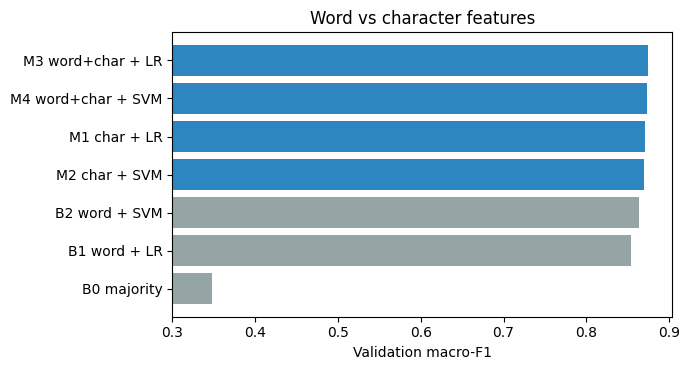

In [9]:
res_clean.to_csv("results/baselines_validation.csv", index=False)
best_name = res_clean[res_clean.model != "B0 majority"].sort_values("val_macro_F1", ascending=False).iloc[0]["model"]
print("Best on validation:", best_name)

# Bar chart of validation macro-F1 (figure for the report)
plot_df = res_clean.sort_values("val_macro_F1")
plt.figure(figsize=(7, 3.8))
plt.barh(plot_df.model, plot_df.val_macro_F1, color=["#2e86c1" if m.startswith("M") else "#95a5a6" for m in plot_df.model])
plt.xlabel("Validation macro-F1"); plt.title("Word vs character features")
plt.xlim(0.3, max(0.9, plot_df.val_macro_F1.max() + 0.03)); plt.tight_layout()
plt.savefig("figures/baseline_macroF1.png", dpi=150); plt.show()

## 5. Imbalance check
The synopsis motivates class weighting with imbalance. The class counts in section 2 show how large the imbalance actually is. This cell measures whether class weights change anything on the best model. **Report whichever result you get**: if there is no real difference, say so and adjust the imbalance argument.

In [10]:
best_est = fitted[best_name]
clf_cls = type(best_est.named_steps["clf"])
C_best = best_est.named_steps["clf"].C

rows = []
for cw in [None, "balanced"]:
    est = clone(best_est)
    est.set_params(clf__class_weight=cw)
    est.fit(train["clean"], train.y)
    rows.append({"class_weight": str(cw), **scores(val.y, est.predict(val["clean"]))})
pd.DataFrame(rows).round(4)

,class_weight,macro_F1,acc,P_hate,R_hate,F1_hate
0,None,0.8711,0.8727,0.8997,0.8177,0.8567
1,balanced,0.8738,0.8752,0.8957,0.8284,0.8607


## 6. Final evaluation on the test set
**Run this once**, after all choices are made on validation. Do not tune anything based on these numbers.

M3 word+char + LR {'macro_F1': 0.8981, 'acc': 0.8987, 'P_hate': 0.895, 'R_hate': 0.8864, 'F1_hate': 0.8907}

                precision    recall  f1-score   support

        Normal      0.902     0.909     0.906      1070
Hate/Offensive      0.895     0.886     0.891       933

      accuracy                          0.899      2003
     macro avg      0.898     0.898     0.898      2003
  weighted avg      0.899     0.899     0.899      2003



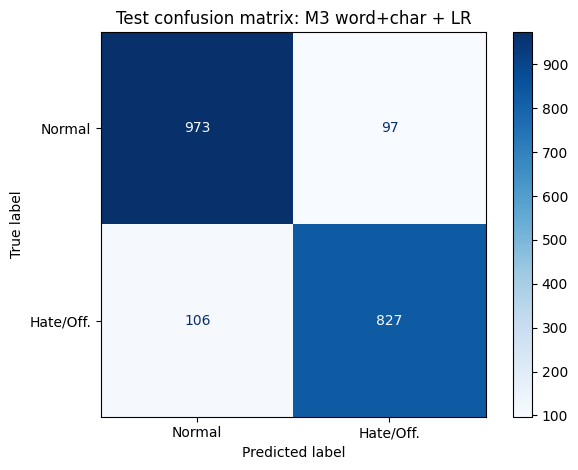

Majority baseline test macro-F1: 0.3482


In [11]:
y_pred_test = best_est.predict(test["clean"])
test_scores = scores(test.y, y_pred_test)
print(best_name, {k: round(v, 4) for k, v in test_scores.items()})
print()
print(classification_report(test.y, y_pred_test, target_names=["Normal", "Hate/Offensive"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(test.y, y_pred_test), display_labels=["Normal", "Hate/Off."]).plot(cmap="Blues")
plt.title(f"Test confusion matrix: {best_name}"); plt.tight_layout()
plt.savefig("figures/test_confusion.png", dpi=150); plt.show()

# Baseline for comparison on the same test set
b0 = DummyClassifier(strategy="most_frequent").fit(train["clean"], train.y)
print("Majority baseline test macro-F1:", round(f1_score(test.y, b0.predict(test["clean"]), average="macro"), 4))

## 7. Calibration
Stage 2 relies on the predicted hate score meaning something, so check how well scores match reality. Platt scaling (a 1-D logistic regression on the model's decision score) is fitted on the **validation** set and its effect is measured on the **test** set. Reliability diagram and Expected Calibration Error (ECE) are reported.

ECE before calibration: 0.0507
ECE after Platt scaling: 0.0282


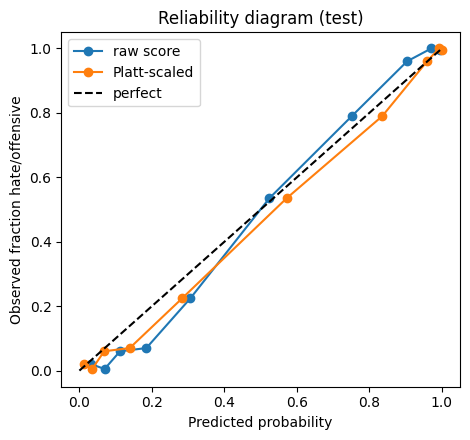

In [12]:
def ece(y_true, p, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.digitize(p, edges[1:-1])
    total = 0.0
    for b in range(bins):
        m = idx == b
        if m.any():
            total += m.mean() * abs(y_true[m].mean() - p[m].mean())
    return total

def raw_scores(est, X):
    return est.decision_function(X).reshape(-1, 1)

# Uncalibrated probabilities: squash the raw decision score with a sigmoid (shown for reference only)
s_val, s_test = raw_scores(best_est, val["clean"]), raw_scores(best_est, test["clean"])
p_test_raw = 1 / (1 + np.exp(-s_test.ravel()))

# Platt scaling fitted on validation
platt = LogisticRegression(C=1e6, solver="lbfgs").fit(s_val, val.y)
p_test_cal = platt.predict_proba(s_test)[:, 1]

print("ECE before calibration:", round(ece(test.y.values, p_test_raw), 4))
print("ECE after Platt scaling:", round(ece(test.y.values, p_test_cal), 4))

plt.figure(figsize=(4.8, 4.5))
for p, lab in [(p_test_raw, "raw score"), (p_test_cal, "Platt-scaled")]:
    frac, mean_p = calibration_curve(test.y, p, n_bins=10, strategy="quantile")
    plt.plot(mean_p, frac, marker="o", label=lab)
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.xlabel("Predicted probability"); plt.ylabel("Observed fraction hate/offensive")
plt.legend(); plt.title("Reliability diagram (test)"); plt.tight_layout()
plt.savefig("figures/reliability.png", dpi=150); plt.show()

## 8. Error analysis, top features, learning curve

In [13]:
# 8a. Misclassified validation tweets: label the 'category' column by hand (aim for 30-50 rows)
val_pred = best_est.predict(val["clean"])
errs = val[val_pred != val.y].copy()
errs["pred"] = val_pred[val_pred != val.y]
errs["error_type"] = np.where((errs.y == 1) & (errs.pred == 0), "missed hate (FN)", "false alarm (FP)")
errs["category"] = ""   # e.g. sarcasm / unseen spelling variant / religious or ethnic term / label noise / code-mixed English
out = errs.sample(min(50, len(errs)), random_state=SEED)[["tweet", "y", "pred", "error_type", "category"]]
out.to_csv("results/error_analysis_to_label.csv", index=False, encoding="utf-8-sig")  # utf-8-sig so Excel on Windows shows emojis
out.to_excel("results/error_analysis_to_label.xlsx", index=False)
print(errs.error_type.value_counts().to_dict())
out.head(10)

{'missed hate (FN)': 64, 'false alarm (FP)': 36}


,tweet,y,pred,error_type,category
675,jb ap ne haq ka sath hi nahi dena to phir ap ke sath yahoodi govt theek hikr rahi hai,1,0,missed hate (FN),
495,koi 10 crore de do yar...me b koi dhang ka kam kr lu😀,1,0,missed hate (FN),
595,"rt : rameez, the incident took place in rotterdam in october. not yahodi kay karnamy.",0,1,false alarm (FP),
425,osama bin laden was also a scholar rahul ..make him your ideal as well and tel this to us goverment wenever u go to us..then will see wh...,1,0,missed hate (FN),
409,ca or cs ma zayda farq ni hota bas ca walun ko phla pta hota ha ka kutyy wali honi ha or cs walon ko ja ka pta lagta ha ka oh shi kht...,1,0,missed hate (FN),
367,he is not an atheist he is an ahmedi or a pro ahmedi atheist,0,1,false alarm (FP),
249,hareem shah aik wahid trend ha jo har thory din ke bad twitter trends ki zeenat banta ha wah hareem shah wah. mujhe lagta ha ke qandeel ...,1,0,missed hate (FN),
655,kreyszig tera bera gharaq ho,1,0,missed hate (FN),
138,shukria bc tyri waja sy bht hasi aj myn wo b talha wali pic ki wja sy😂😂😂😝,1,0,missed hate (FN),
0,"😎🇵🇰😎 diesel's """"""hidden""""""warning...😎🇵🇰😎 guess to whom.. 😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁😁pagal ho gaya hay...let c, geeder...",1,0,missed hate (FN),


In [14]:
# 8b. Most influential features (linear models only)
feat_names = best_est.named_steps["feat"].get_feature_names_out()
coefs = best_est.named_steps["clf"].coef_.ravel()
order = np.argsort(coefs)
print("Strongest NORMAL indicators:", [feat_names[i] for i in order[:25]])
print()
print("Strongest HATE/OFFENSIVE indicators:", [feat_names[i] for i in order[::-1][:25]])

Strongest NORMAL indicators: ['word__thi', 'word__bhai', 'char__ 😂', 'word__ap', 'word__as', 'char__ 😂 ', 'word__aap', 'word__meri', 'word__na ho', 'char__😂 ', 'word__hum', 'word__na', 'word__apke', 'word__dil', 'word__march', 'word__say', 'word__baat', 'word__i am', 'word__on the', 'word__ham', 'char__me', 'word__bandi', 'word__mat', 'word__am', 'word__main']

Strongest HATE/OFFENSIVE indicators: ['word__bc', 'word__bhenchod', 'word__randi', 'word__bharwe', 'char__bc', 'char__ bc', 'char__nd', 'char__od', 'word__bhaunk', 'word__rundi', 'char__bc ', 'word__hijra', 'word__ahmaq', 'char__rand', 'word__saali', 'char__ bc ', 'char__c ', 'char__hod', 'char__ rand', 'char__and', 'word__gashti', 'char__chod', 'char__ ran', 'char__ndi', 'word__harami']


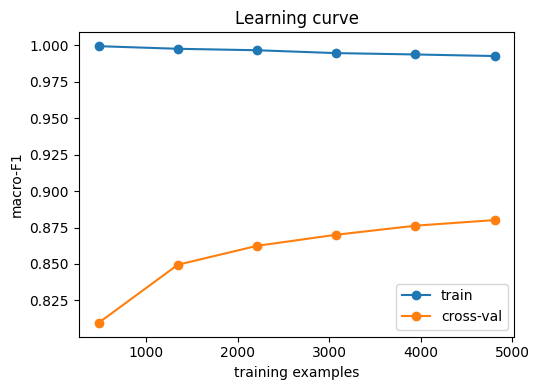

In [15]:
# 8c. Learning curve: does more data still help? (supports the low-resource argument)
sizes, tr, va = learning_curve(clone(best_est), train["clean"], train.y,
                               train_sizes=np.linspace(0.1, 1.0, 6), cv=3,
                               scoring="f1_macro", n_jobs=-1, random_state=SEED, shuffle=True)
plt.figure(figsize=(5.5, 4))
plt.plot(sizes, tr.mean(axis=1), marker="o", label="train")
plt.plot(sizes, va.mean(axis=1), marker="o", label="cross-val")
plt.xlabel("training examples"); plt.ylabel("macro-F1"); plt.legend()
plt.title("Learning curve"); plt.tight_layout()
plt.savefig("figures/learning_curve.png", dpi=150); plt.show()

## 9. Save outputs for Stage 2

In [16]:
joblib.dump({"model": best_est, "platt": platt, "name": best_name}, "results/stage1_model.joblib")
final = res_clean.copy()
final.to_csv("results/baselines_validation.csv", index=False)
pd.Series({"best_model": best_name, **{f"test_{k}": round(v, 4) for k, v in test_scores.items()}}).to_csv("results/final_test.csv")
print("Saved: results/stage1_model.joblib, results/baselines_validation.csv, results/final_test.csv, results/error_analysis_to_label.csv")

Saved: results/stage1_model.joblib, results/baselines_validation.csv, results/final_test.csv, results/error_analysis_to_label.csv


## 10. Code-switch density analysis (the project's distinctive diagnostic)
**Question:** does the model get worse as a tweet contains more English?

**Definition.** `density = (# English tokens) / (# alphabetic tokens)` in the cleaned tweet. A token counts as English if it is in the NLTK word list **and** is reasonably common in English (wordfreq Zipf >= 3.0) **and** is not on a hand-made list of Roman Urdu words that collide with English (`to`, `me`, `main`, `ho`, `hi`, `tum`, `hum`, `ka`, ...). Collisions make the heuristic conservative: it under-counts English slightly, and it still mislabels some words (for example `bare`, which is Roman Urdu for "big").

**Bins** (fixed thresholds, because about a third of tweets have density 0 and quantile bins would tie): low (< 10% English), medium (10-40%), high (> 40%).

**Important:** hand-check the heuristic (the spot-check file below) and report its accuracy.

In [17]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "wordfreq"], check=False)
import nltk
nltk.download("words", quiet=True)
from nltk.corpus import words as nltk_words
from wordfreq import zipf_frequency

# Roman Urdu words that are also English dictionary words (kept OUT of the English count)
COLLISIONS = set('''ko to ka ho se ye na ha tu me or hi tha jo koi he main tum wo ab ni hy ne ga mein ya log
ma do say us hum par per de bat mat jab han lo hu di aa hay gi kay agar un mere nay sa hon hun bas ban hen mar ge
lag bar mil gay abe hui beta ham ata tab aye sub yr es re sun pay sara ur chore band sid li fir banda hath hone hue
ji sale din khan allah islam hindu india pakistani indian nasal ly bare'''.split())

EN_DICT = set(w.lower() for w in nltk_words.words())

def is_english(tok):
    return len(tok) > 1 and tok in EN_DICT and zipf_frequency(tok, "en") >= 3.0 and tok not in COLLISIONS

def code_switch_density(text):
    toks = re.findall(r"[a-z]+", text)
    return 0.0 if not toks else sum(is_english(t) for t in toks) / len(toks)

BIN_EDGES  = [-0.01, 0.10, 0.40, 1.01]
BIN_LABELS = ["low (<10%)", "medium (10-40%)", "high (>40%)"]
for d in (train, val, test):
    d["density"] = d["clean"].map(code_switch_density)
    d["cs_bin"] = pd.cut(d["density"], bins=BIN_EDGES, labels=BIN_LABELS)

dist = pd.concat({s: d.groupby("cs_bin").agg(n=("y", "size"), pct_hate=("y", "mean"))
                  for s, d in [("train", train), ("val", val), ("test", test)]}, axis=1).round(3)
display(dist)

train           val           test         
                    n pct_hate    n pct_hate     n pct_hate
cs_bin                                                     
low (<10%)       3798    0.508  430    0.540  1033    0.521
medium (10-40%)  2665    0.418  293    0.392   775    0.410
high (>40%)       746    0.420   78    0.333   195    0.395

### Results by density bin
Macro-F1 with a 95% bootstrap confidence interval (1,000 resamples within each bin). Bins have different sizes, so the intervals matter: a difference smaller than the interval width is not a finding.

,split,bin,n,pct_hate,macro_F1,CI_low,CI_high,P_hate,R_hate
0,val,low (<10%),430,0.540,0.907,0.878,0.934,0.957,0.866
1,val,medium (10-40%),293,0.392,0.834,0.791,0.877,0.817,0.774
2,val,high (>40%),78,0.333,0.798,0.700,0.888,0.731,0.731
3,test,low (<10%),1033,0.521,0.921,0.905,0.938,0.930,0.918
4,test,medium (10-40%),775,0.410,0.884,0.862,0.907,0.871,0.852
5,test,high (>40%),195,0.395,0.814,0.752,0.864,0.756,0.805


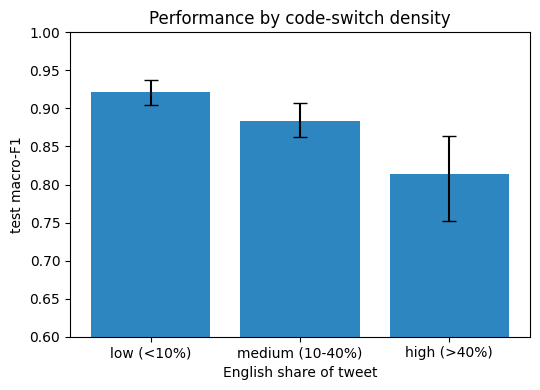

In [18]:
rng = np.random.default_rng(SEED)

def boot_ci(y, p, n=1000):
    y, p = np.asarray(y), np.asarray(p)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(y), len(y))
        vals.append(f1_score(y[idx], p[idx], average="macro"))
    return np.percentile(vals, [2.5, 97.5])

rows = []
for split_name, d in [("val", val), ("test", test)]:
    d["pred"] = best_est.predict(d["clean"])
    for b, g in d.groupby("cs_bin"):
        lo, hi = boot_ci(g.y, g.pred)
        rows.append({"split": split_name, "bin": b, "n": len(g), "pct_hate": round(g.y.mean(), 3),
                     "macro_F1": round(f1_score(g.y, g.pred, average="macro"), 3),
                     "CI_low": round(lo, 3), "CI_high": round(hi, 3),
                     "P_hate": round(precision_score(g.y, g.pred, pos_label=1, zero_division=0), 3),
                     "R_hate": round(recall_score(g.y, g.pred, pos_label=1), 3)})
by_bin = pd.DataFrame(rows)
by_bin.to_csv("results/code_switch_by_bin.csv", index=False)
display(by_bin)

t = by_bin[by_bin.split == "test"]
plt.figure(figsize=(5.5, 4))
plt.bar(t["bin"].astype(str), t.macro_F1,
        yerr=[t.macro_F1 - t.CI_low, t.CI_high - t.macro_F1], capsize=5, color="#2e86c1")
plt.ylim(0.6, 1.0); plt.ylabel("test macro-F1"); plt.xlabel("English share of tweet")
plt.title("Performance by code-switch density"); plt.tight_layout()
plt.savefig("figures/code_switch_macroF1.png", dpi=150); plt.show()

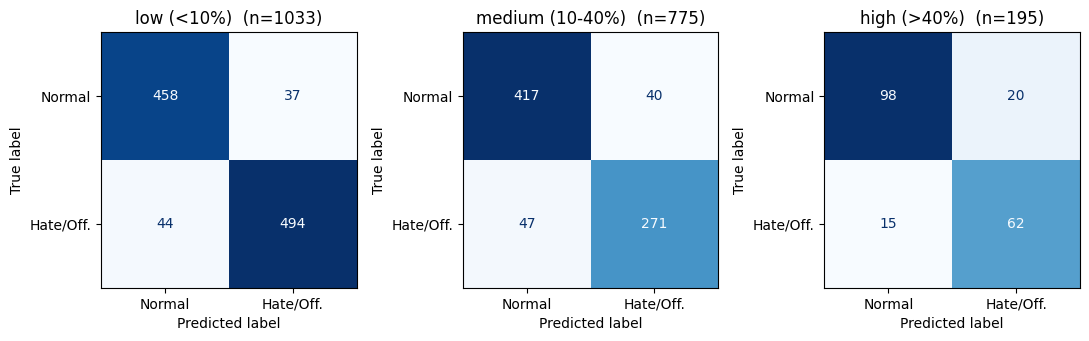

In [19]:
# Confusion matrix per density bin (test set)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (b, g) in zip(axes, test.groupby("cs_bin")):
    ConfusionMatrixDisplay(confusion_matrix(g.y, g.pred, labels=[0, 1]),
                           display_labels=["Normal", "Hate/Off."]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{b}  (n={len(g)})")
plt.tight_layout(); plt.savefig("figures/code_switch_confusion.png", dpi=150); plt.show()

### Spot-check the heuristic (do this by hand)
Fill in `your_bin` (low / medium / high) from your own reading of each tweet, then run the next cell to get the heuristic's agreement with you.

In [20]:
spot = test.sample(50, random_state=SEED)[["tweet", "density", "cs_bin"]].copy()
spot["density"] = spot["density"].round(2)
spot["your_bin"] = ""
spot.to_excel("results/density_spotcheck.xlsx", index=False)
print("Saved results/density_spotcheck.xlsx. Fill the your_bin column, then upload it and run the next cell.")

Saved results/density_spotcheck.xlsx. Fill the your_bin column, then upload it and run the next cell.


In [21]:
# Run AFTER filling in results/density_spotcheck.xlsx
if os.path.exists("results/density_spotcheck.xlsx"):
    chk = pd.read_excel("results/density_spotcheck.xlsx")
    chk = chk[chk["your_bin"].astype(str).str.strip().str.lower().isin(["low", "medium", "high"]) | chk["your_bin"].astype(str).str.contains("low|medium|high", case=False)]
    if len(chk):
        chk["h"] = chk["your_bin"].astype(str).str.lower().str.extract(r"(low|medium|high)")[0]
        chk["m"] = chk["cs_bin"].astype(str).str.extract(r"(low|medium|high)")[0]
        print("Heuristic agrees with you on", round((chk.h == chk.m).mean() * 100, 1), "% of", len(chk), "tweets")
        display(pd.crosstab(chk.h, chk.m, rownames=["you"], colnames=["heuristic"]))
    else:
        print("your_bin column is still empty")

your_bin column is still empty


### Sensitivity check: does the finding depend on the thresholds?
The 10% / 40% cut-offs are a judgement call, and the spot-check showed the heuristic over-counts English near the low/medium boundary. Re-run the by-bin test results with several cut-off pairs. If macro-F1 still falls as English share rises under every pair, the finding does not hinge on one threshold. The last column bootstraps the gap between the lowest and highest bin.

In [22]:
THRESHOLDS = [(0.10, 0.40), (0.15, 0.40), (0.20, 0.40), (0.20, 0.50), (0.10, 0.30), (0.25, 0.50)]
rng = np.random.default_rng(SEED)

def macro_f1(y, p):
    return f1_score(y, p, average="macro")

rows = []
for lo_t, hi_t in THRESHOLDS:
    b = np.where(test.density <= lo_t, "low", np.where(test.density <= hi_t, "medium", "high"))   # same edges as pd.cut above
    y, p = test.y.values, test.pred.values
    m = {k: (b == k) for k in ["low", "medium", "high"]}
    f = {k: macro_f1(y[m[k]], p[m[k]]) for k in m}
    gaps = []
    for _ in range(1000):
        il = rng.choice(np.where(m["low"])[0], m["low"].sum())
        ih = rng.choice(np.where(m["high"])[0], m["high"].sum())
        gaps.append(macro_f1(y[il], p[il]) - macro_f1(y[ih], p[ih]))
    g_lo, g_hi = np.percentile(gaps, [2.5, 97.5])
    rows.append({"low<": lo_t, "high>=": hi_t,
                 "n_low": m["low"].sum(), "n_med": m["medium"].sum(), "n_high": m["high"].sum(),
                 "F1_low": round(f["low"], 3), "F1_med": round(f["medium"], 3), "F1_high": round(f["high"], 3),
                 "gap_low_minus_high": round(f["low"] - f["high"], 3),
                 "gap_CI_low": round(g_lo, 3), "gap_CI_high": round(g_hi, 3)})
sens = pd.DataFrame(rows)
sens.to_csv("results/code_switch_sensitivity.csv", index=False)
display(sens)
print("High-English bin below the low-English bin under every threshold pair:", bool((sens.gap_CI_low > 0).all()))
print("Low > medium > high (fully monotone) under every pair:", bool(((sens.F1_low > sens.F1_med) & (sens.F1_med > sens.F1_high)).all()))

,low<,high>=,n_low,n_med,n_high,F1_low,F1_med,F1_high,gap_low_minus_high,gap_CI_low,gap_CI_high
0,0.10,0.4,1033,775,195,0.921,0.884,0.814,0.107,0.051,0.170
1,0.15,0.4,1286,522,195,0.907,0.903,0.814,0.093,0.037,0.151
2,0.20,0.4,1491,317,195,0.903,0.920,0.814,0.089,0.032,0.148
3,0.20,0.5,1491,383,129,0.903,0.910,0.784,0.119,0.049,0.193
4,0.10,0.3,1033,670,300,0.921,0.880,0.846,0.076,0.036,0.125
5,0.25,0.5,1615,259,129,0.905,0.905,0.784,0.121,0.048,0.194


High-English bin below the low-English bin under every threshold pair: True
Low > medium > high (fully monotone) under every pair: False


## 11. Subword model and significance tests
**Subword model.** A SentencePiece BPE tokenizer is trained on the training tweets only (unlabelled text), tweets are split into subword pieces, and TF-IDF over piece unigrams and bigrams feeds a Logistic Regression. This is the project's subword representation (see Bojanowski et al., 2017, and Sennrich et al., 2016 for the idea). Two vocabulary sizes are compared. Because the tokenizer is trained on the full training set before cross-validation, the unlabelled vocabulary sees the validation folds. The effect is small, and the validation set is untouched.

**Significance tests.** Differences between feature sets can be small, so the main comparisons are tested on the test set with (a) an exact McNemar test on paired predictions and (b) a paired bootstrap of the macro-F1 difference. These tests are used to interpret results, not to choose models.

In [23]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentencepiece"], check=False)
import sentencepiece as spm
from sklearn.preprocessing import FunctionTransformer

os.makedirs("sp", exist_ok=True)
with open("sp/train_text.txt", "w", encoding="utf-8") as f:
    for t in train["clean"]:
        f.write(t.replace("\n", " ") + "\n")

SP_MODELS = {}
def sp_pieces(texts):
    return [" ".join(SP_MODELS[CURRENT_SP].encode(t, out_type=str)) for t in texts]

rows, sp_fitted = [], {}
for vocab in [2000, 8000]:
    prefix = f"sp/bpe_{vocab}"
    spm.SentencePieceTrainer.train(input="sp/train_text.txt", model_prefix=prefix, vocab_size=vocab,
                                   model_type="bpe", character_coverage=1.0, hard_vocab_limit=False)
    SP_MODELS[vocab] = spm.SentencePieceProcessor(model_file=prefix + ".model")
    CURRENT_SP = vocab
    pipe = Pipeline([("pieces", FunctionTransformer(sp_pieces)),
                     ("feat", TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
                     ("clf", LR())])
    gs = GridSearchCV(pipe, GRID, scoring="f1_macro", cv=cv, n_jobs=1, refit=True)
    gs.fit(train["clean"], train.y)
    i = gs.best_index_
    name = f"S{vocab} subword (BPE {vocab}) + LR"
    rows.append({"model": name, "cv_macro_F1": gs.cv_results_["mean_test_score"][i],
                 "cv_std": gs.cv_results_["std_test_score"][i], "best_C": gs.best_params_["clf__C"],
                 **scores(val.y, gs.predict(val["clean"]))})
    sp_fitted[name] = (vocab, gs.best_estimator_)
    print("done:", name)
subword_res = pd.DataFrame(rows).round(4)
subword_res.to_csv("results/subword_validation.csv", index=False)
subword_res

done: S2000 subword (BPE 2000) + LR
done: S8000 subword (BPE 8000) + LR


,model,cv_macro_F1,cv_std,best_C,macro_F1,acc,P_hate,R_hate,F1_hate
0,S2000 subword (BPE 2000) + LR,0.8584,0.0045,10,0.8563,0.8577,0.8711,0.8150,0.8421
1,S8000 subword (BPE 8000) + LR,0.8565,0.0055,10,0.8485,0.8502,0.8688,0.7989,0.8324


In [24]:
from scipy.stats import binomtest

def predict_any(name, X):
    if name in fitted:
        return fitted[name].predict(X)
    vocab, est = sp_fitted[name]
    global CURRENT_SP
    CURRENT_SP = vocab
    return est.predict(X)

best_sp = max(sp_fitted, key=lambda n: subword_res.set_index("model").loc[n, "macro_F1"])
PAIRS = [("B1 word + LR", "M1 char + LR"),
         ("B2 word + SVM", "M2 char + SVM"),
         ("B1 word + LR", "M3 word+char + LR"),
         ("M1 char + LR", "M3 word+char + LR"),
         ("M1 char + LR", best_sp)]

rng = np.random.default_rng(SEED)
y = test.y.values
sig_rows = []
for a, b in PAIRS:
    pa, pb = predict_any(a, test["clean"]), predict_any(b, test["clean"])
    ca, cb = (pa == y), (pb == y)
    n01 = int((ca & ~cb).sum())      # A right, B wrong
    n10 = int((~ca & cb).sum())      # A wrong, B right
    p_mc = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
    diffs = []
    for _ in range(1000):
        idx = rng.integers(0, len(y), len(y))
        diffs.append(macro_f1(y[idx], pb[idx]) - macro_f1(y[idx], pa[idx]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    sig_rows.append({"A": a, "B": b, "F1_A": round(macro_f1(y, pa), 4), "F1_B": round(macro_f1(y, pb), 4),
                     "diff_B_minus_A": round(macro_f1(y, pb) - macro_f1(y, pa), 4),
                     "boot_CI_low": round(lo, 4), "boot_CI_high": round(hi, 4),
                     "A_right_B_wrong": n01, "A_wrong_B_right": n10, "McNemar_p": round(p_mc, 4)})
sig = pd.DataFrame(sig_rows)
sig.to_csv("results/significance_tests.csv", index=False)
sig

,A,B,F1_A,F1_B,diff_B_minus_A,boot_CI_low,boot_CI_high,A_right_B_wrong,A_wrong_B_right,McNemar_p
0,B1 word + LR,M1 char + LR,0.8755,0.8929,0.0174,0.0043,0.0300,74,109,0.0118
1,B2 word + SVM,M2 char + SVM,0.8795,0.8958,0.0163,0.0037,0.0305,78,111,0.0197
2,B1 word + LR,M3 word+char + LR,0.8755,0.8981,0.0226,0.0120,0.0331,37,82,0.0000
3,M1 char + LR,M3 word+char + LR,0.8929,0.8981,0.0052,-0.0027,0.0133,29,39,0.2750
4,M1 char + LR,S2000 subword (BPE 2000) + LR,0.8929,0.8740,-0.0189,-0.0309,-0.0069,95,57,0.0026


## Next steps
- Hand-check the density heuristic (spot-check file) and report its accuracy.
- Stage 2: apply `stage1_model.joblib` to the Negative messages of the sentiment corpus (deduplicate against the RUHSOLD test set first).